# 01 · Data Audit (Phase 1)
**Project:** Explainable Machine Learning for SMS Scam Detection in the Kenyan Mobile Money Context
**Deliverable of this notebook:** a cleaned, documented dataset (`data/cleaned_messages.csv`) plus a written record of every cleaning decision.

### Why an audit comes first
The whole project is a *rigorous, leakage-aware* evaluation. Leakage mostly originates in the data (the same message appearing in both training and test sets), so before any model is built we must know exactly what is in the file: size, class balance, repeated messages, contradicting labels, and how the auxiliary field `prelabel` relates to the target `label`.

### How to read this notebook
Each section has: **Question → Evidence (code) → Decision & reasoning**. The decisions are summarised in a table at the end.

In [1]:
import sys; sys.path.insert(0, '..')   # makes src/ importable when the notebook runs from notebooks/
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.preprocessing import load_raw, clean_dataset, normalize_text, near_duplicate_groups, RANDOM_STATE
pd.set_option('display.max_colwidth', 140, 'display.width', 200)
sns.set_theme(style='whitegrid')
df = load_raw('../data/scam_detection_labeled.csv')
print(df.shape)
df[['message_content','prelabel','label']].head()

(736, 5)

,message_content,prelabel,label
0,"Christa, finish your account sign-up and you could make Ksh 287 hourly in Nairobi. * t.uber.com/lJ8929 Reply STOP 2 to +1 415-237-0403 t...",2: High-risk scam,scam
1,"CONGRATULATION!\nYOUR ACCOUNT 254757547986 HAS BEEN CREDITED WITH KES 62,950\n\nNew BONUS Balance: KES 62,950 \n\nLOGIN>wekelea.com\n \...",2: High-risk scam,scam
2,🙏🙏 I can do all this through him who gives me strength. Phil 4;13 Reply with 20 To stop this message reply with STOP,0: Legit (Low-risk),legit
3,"Hi, I'm Alice, a recruiter at VG Investments. We are looking for a responsible part-time partner to join VG Investment Group. Join us an...",2: High-risk scam,scam
4,"TAL6FH2DN CONFIRMED, YOU HAVE RECEIVED KES. 70,350\n\nUSIPITWE NA HII CHEPKORIR INGIA> pepea.ke\n\nSHARE YAKO INAKUNGOJA LEO\n\nDEPOSIT ...",2: High-risk scam,scam


## 1. Structure, types and missing values
**Question:** Is the file what the brief says it is (three columns; `label` is the target; `message_content` the input)?

In [2]:
print(df[['message_content','prelabel','label']].dtypes)
print('\nMissing values per column:'); print(df[['message_content','prelabel','label']].isna().sum())
print('\nEmpty / whitespace-only messages:', (df.message_content.str.strip()=='').sum())

message_content    str
prelabel           str
label              str
dtype: object

Missing values per column:
message_content    0
prelabel           0
label              0
dtype: int64

Empty / whitespace-only messages: 0

**Finding:** 736 rows, 3 columns, no missing values, no empty messages.
**Decision:** no imputation or row removal is required for missingness. The target is `label` (`scam`=1 is the *positive class*, `legit`=0). We make scam the positive class so that *recall* and *precision* mean exactly what the brief defines: "of all actual scams, how many did we catch" and "of all flagged messages, how many were scams".

## 2. Reconciling the file with the published description
**Question:** The brief says the published dataset has **738** messages (**427** scam, 311 legit) while our file was reported to have **736** (425 scam, 311 legit). Is that true, and what does it imply?

In [3]:
pub = {'total':738,'scam':427,'legit':311}
mine = {'total':len(df),'scam':int((df.label=='scam').sum()),'legit':int((df.label=='legit').sum())}
pd.DataFrame({'published':pub,'our file':mine,'difference':{k:mine[k]-pub[k] for k in pub}})

,published,our file,difference
total,738,736,-2
scam,427,425,-2
legit,311,311,0


**Finding:** our file has 736 rows: 2 fewer than published, and both missing rows are *scam*; the legit count matches exactly (311).

**Decision / reasoning:** I cannot download the original source from this offline environment, so I **cannot verify which two scam rows differ**. Rather than silently treating the two as identical, I document the discrepancy and carry it as a *limitation*: our results are about *this 736-row file*, not necessarily the published 738-row version. Two plausible explanations (unverified): the authors removed two rows (e.g. unreadable/empty) when exporting the CSV, or the description counts two rows that were merged in export. Either way a 2-row difference (0.3%) is far too small to change conclusions, and nothing in the later modelling depends on it.

## 3. Class distribution
**Question:** How imbalanced is the target?

label
scam     425
legit    311
Name: count, dtype: int64
label
scam     0.577
legit    0.423
Name: count, dtype: float64

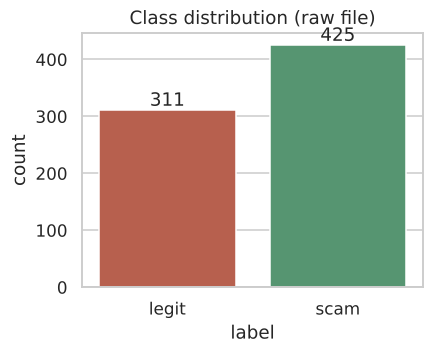

In [4]:
vc = df.label.value_counts(); print(vc); print((vc/len(df)).round(3))
fig,ax=plt.subplots(figsize=(4,3)); sns.countplot(data=df,x='label',order=['legit','scam'],ax=ax,palette=['#4c9f70','#c8553d'],hue='label',legend=False)
for p in ax.patches: ax.annotate(int(p.get_height()),(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom')
ax.set_title('Class distribution (raw file)'); plt.show()

**Finding:** ~58% scam / 42% legit. This is *mild* imbalance, not the severe imbalance (e.g. 1% fraud) that normally requires resampling.

**Decision:** **no oversampling/SMOTE.** Reasons: (i) the imbalance is mild; (ii) resampling text before splitting is a classic leakage source and synthetic text is hard to justify; (iii) we will instead (a) use *stratified* splits so each fold keeps the ratio, (b) report recall/precision/F1/ROC-AUC rather than accuracy alone, and (c) treat `class_weight` as a tunable hyper-parameter and choose the decision *threshold* explicitly (brief section 9).
Note also: this ratio reflects how the dataset was *collected*, not the real-world share of scam SMS (in a real inbox legit messages vastly outnumber scams). Precision in deployment will therefore be lower than what we measure here - an important limitation.

## 4. Duplicates - the central audit
The brief states: *89 fully duplicated rows* and *91 repeated message contents*, and warns that these are **not interchangeable**. Let us verify both numbers and explain the gap.

In [5]:
full_dup = df.duplicated(subset=['message_content','prelabel','label']).sum()
text_dup = df.duplicated(subset=['message_content']).sum()
print('Rows that are an exact repeat of an earlier row (text+prelabel+label):', full_dup)
print('Rows whose message text repeats an earlier row (any label)          :', text_dup)
print('Difference:', text_dup-full_dup)

Rows that are an exact repeat of an earlier row (text+prelabel+label): 89
Rows whose message text repeats an earlier row (any label)          : 91
Difference: 2

**Finding:** both figures from the brief are confirmed (89 and 91). They differ by 2 because "repeated *content*" ignores the label, while "fully duplicated row" requires the label to match too. So **2 repeats are texts that were annotated with different labels** - next we inspect them.

### 4a. Conflicting labels - same text, different label

In [6]:
nlab = df.groupby('message_content').label.nunique()
conf_texts = nlab[nlab>1].index
conf = df[df.message_content.isin(conf_texts)][['message_content','prelabel','label']].sort_values('message_content')
conf['message_content']=conf.message_content.str[:130]
conf

,message_content,prelabel,label
61,"Dear Customer, Reply with1 to set shukran ya Rab by nasheed as your Skiza Tune. Reply with2 to set NI MUNGU by JOHN M as your S",0: Legit (Low-risk),legit
187,"Dear Customer, Reply with1 to set shukran ya Rab by nasheed as your Skiza Tune. Reply with2 to set NI MUNGU by JOHN M as your S",2: High-risk scam,scam
36,The process is immediate once you make the payment as your payment is acts as the initializer to the process for verification,1: Moderate-risk scam,scam
285,The process is immediate once you make the payment as your payment is acts as the initializer to the process for verification,0: Legit (Low-risk),legit


**Finding:** exactly **2 distinct texts (4 rows)** carry both a `scam` and a `legit` label. One is a Safaricom *Skiza tune* promotional template; the other is a generic sentence ("the process is immediate once you make the payment...") that can be either a scam or an innocent reply depending on context.

**Decision: remove all 4 rows.** Options considered:
| Option | Why rejected / accepted |
|---|---|
| Keep both rows | The model would be asked to predict two different answers for identical input; and if one copy lands in train and one in test, one of them is *guaranteed* wrong - it measures annotation noise, not model quality. |
| Pick one label (e.g. majority/first) | Arbitrary; with a 1-vs-1 tie there is no majority, and we cannot verify the truth. |
| **Drop the text entirely (chosen)** | Honest: we cannot know the correct label. Cost is only 4 rows (0.5%). |
The removed rows are recorded in `reports/removed_conflicting_rows.csv` for transparency.

### 4b. Does text normalisation reveal *more* hidden duplicates?
Two messages that differ only by case or whitespace/newlines are effectively the same message. We compare raw-text duplication with duplication after a light normalisation (lower-case, collapse whitespace).

In [7]:
raw_unique = df.message_content.nunique(); norm_unique = df.text_key.nunique()
print('unique raw texts       :', raw_unique)
print('unique normalised texts:', norm_unique)
print('extra duplicates found by normalising:', raw_unique-norm_unique)

unique raw texts       : 645
unique normalised texts: 645
extra duplicates found by normalising: 0

**Finding:** normalising whitespace/case finds **no additional** exact duplicates (736-91 = 645 unique either way). I still keep the normalised key (`text_key`) as the duplicate-detection key because it is free, safe, and protects against this problem if the data is ever extended. Crucially, the *model* still sees the original message text (with its capitalisation and punctuation) - capitalisation like "CONGRATULATIONS" is itself a scam signal, so we do not destroy it.

### 4c. The most repeated messages

In [8]:
top = df.groupby('text_key').agg(n=('label','size'), label=('label','first'), example=('message_content','first')).sort_values('n',ascending=False).head(8)
top['example']=top.example.str[:110].str.replace('\n',' ')
top

,n,label,example
text_key,,,
"the lord is my strength and my defense; he has\nbecome my salvation, psalms 118:14, reply with\n44 to spread this message of encouragement.\nto entertain your callers with blessed is the one\nwho takes refuge in the lord"" dial *811*608#""",8,legit,"The Lord is my strength and my defense; he has\nbecome my salvation, Psalms 118:14, Reply with\n44 to spread t"
2025,4,legit,2025
"mungu mpendwa, naomba ulinde watoto wangu. waongoze kwenye njia iliyo sawa na walinde kutokana na hatari. wajaze hekima na ujasiri. familia yetu iwe kimbilio la upendo na amani. amina. jibu na 2 ili kueneza ujumbe huu kwa wengine. bonyeza*875*353# kupata niponye mungu kama skiza. ili usipokee tena jumbe hizi, jibu stop.",4,legit,"Mungu mpendwa, naomba ulinde watoto wangu. Waongoze kwenye njia iliyo sawa na walinde kutokana na hatari. Waja"
"4 11 1 chronicles 16:11 look to the lord and\nhis strength; seek his face always."" reply with\n13 to set as your signature. reply with stop to\nstop receivng this message""",3,legit,"4 11 1 Chronicles 16:11 Look to the LORD and\nhis strength; seek his face always."" Reply with\n13 to set as yo"
"notice!\ndear tenant.\n\nwe are writing to let you know about a significant modification to our rent payment procedure. effective from this september all rent payments will be done through:\n\nlipa na mpesa \npay bill \nbusiness number 4140727\naccount number ( your name or house number)\nname : prosperity services \n\ncash or any other mode of payment will not be accepted deadline 5th september.\n\nregards,\nmanagement.",3,scam,NOTICE!\nDear tenant.\n\nWe are writing to let you know about a significant modification to our rent payment p
"hey, do you have problem with missing marks, incomplete marks or want to upgrade results in your transcript?",3,legit,"Hey, do you have problem with missing marks, incomplete marks or want to upgrade results in your transcript?"
"tc61vwbijz confirmed.you have received ksh5,880.00 from ali juma on 6/3/25.new mpesa balance is ks*(locked)*.to unlock dial *35*0000*16#",3,scam,"TC61VWBIJZ Confirmed.You have received Ksh5,880.00 From ALI JUMA on 6/3/25.New MPESA balance is Ks*(LOCKED)*."
"[zuricash] you have successfully logged in, apply and receive up to 50,000 by clicking https://bit.ly/3rfehdu, or contact us: 0207905232. stop*456*9*5#",3,scam,"[Zuricash] You have successfully logged in, apply and receive up to 50,000 by clicking https://bit.ly/3rFEHdU,"


**Finding:** one Bible-verse / "reply with 44" Skiza promo appears 8 times; several scam templates appear 3-4 times. This is the leakage risk in numbers: with a *random* split, a message that occurs 8 times will almost certainly have copies in both train and test, and the model gets "tested" on text it memorised.

**Decision: keep one copy of each distinct message** (first occurrence). Reasoning: repeated copies add no new information, inflate the apparent size of the dataset, and over-weight a few templates during training. Collapsing also means a duplicate can never straddle train/test at the exact-text level. (Notebook 03 *measures* how much duplicates inflate scores, as a research contribution, by also evaluating on the raw un-deduplicated data.)

## 5. Near-duplicates (template messages)
Exact-text de-duplication is necessary but not sufficient: SMS spam is generated from templates. E.g. *"You still have KSh 8153.12 commission..."* and *"...KSh 9153.12 commission..."* differ by one digit yet are really the same message. If one lands in training and the other in testing, it is still leakage.

**Approach:** compute character n-gram TF-IDF vectors, link every pair of messages with cosine similarity >= threshold, and take connected components as **groups**. All members of a group are then kept on the same side of any split (grouped splitting). This step uses *no labels*, and the vectoriser here is used only to decide grouping, never as a model feature.

In [9]:
clean, audit = clean_dataset(df)
rows=[]
for t in [0.6,0.7,0.8,0.9,0.95]:
    g = near_duplicate_groups(clean.message_content, t)
    sizes = pd.Series(g).value_counts()
    rows.append(dict(threshold=t, n_groups=len(sizes), largest_group=sizes.max(), rows_in_multi_member_groups=int(sizes[sizes>1].sum())))
pd.DataFrame(rows)

,threshold,n_groups,largest_group,rows_in_multi_member_groups
0,0.60,532,22,158
1,0.70,560,11,129
2,0.80,599,7,76
3,0.90,615,4,50
4,0.95,621,4,40


In [10]:
clean['group'] = near_duplicate_groups(clean.message_content, 0.8)
sizes = clean.group.value_counts()
big = sizes[sizes>=3].index[:3]
for g in big:
    print(f'--- group {g} (size {sizes[g]}) ---')
    for t,l in clean[clean.group==g][['message_content','label']].head(4).values: print(f'  [{l}]', t[:120].replace('\n',' '))

--- group 374 (size 7) ---
  [scam] Reply with2 to set KUMALO by JOHN as your Skiza Tune.  Relive historic moments with Skiza. Dial *811*4#  to set Today In
  [scam] Dear Customer,  Reply with1 to set NI MUNGU by JOHN M as your Skiza Tune.   Reply with2 to set Yatapita by SALAF as your
  [scam] Dear Customer,  Reply with1 to set PSALM 34.18 by PSALM 34.18 as your Skiza Tune.   Reply with2 to set shukran ya Rab by
  [scam] Dear Customer,  Reply with1 to set PSALM 34.18 by PSALM 34.18 as your Skiza Tune.   Reply with2 to set mimi by shiriyow 
--- group 42 (size 4) ---
  [scam] NOTICE!\n\nDear tenant ,,\nClear Your Rent Balances NOW  9th Sept 2024.\nAll rent payments should be paid to our DTB BAN
  [scam] NOTICE!\n\nDear tenant ,,\nClear Your Rent Balances NOW  9th Sept 2024.\nAll rent payments should be paid to our DTB BAN
  [scam] Dear tenant ,,\nClear Your Rent Balances NOW  9th Sept 2024.\nAll rent payments should be paid to our DTB BANK account b
  [scam] NOTICE!\n\nDear tenant ,,\nC

**Decision: threshold = 0.8.** It is a judgement call between two failure modes: too low (0.6) glues together merely *similar-topic* messages into huge groups, which removes genuine variety from training; too high (0.95) only catches almost-identical texts and lets template variants leak. The printed groups show 0.8 captures genuine template families (same promo, different number/name) without merging unrelated messages. A sensitivity check on this threshold is run in notebook 03.

### 5a. Do near-duplicate groups ever contain *both* labels?

In [11]:
gl = clean.groupby('group').label.nunique()
mixed = gl[gl>1].index
print('Groups containing both scam and legit messages:', len(mixed))
for g in mixed:
    sub = clean[clean.group==g]
    print(f'\n--- group {g}: {sub.label.value_counts().to_dict()} ---')
    for t,l in sub[['message_content','label']].head(4).values: print(f'  [{l}]', t[:150].replace('\n',' '))

Groups containing both scam and legit messages: 3

--- group 43: {'scam': 1, 'legit': 1} ---
  [scam] KCB   M-PESA LOANS is now available to all M-PESA users 10% interest from\n5,000/=\n10,000/=\n20,000/=\n50,000/=\n100,000/=\nTo apply send 555555 to 0
  [legit] KCB LOAN is available to all M-PESA users 21% interest from\n5,000/=\n10,000/=\n20,000/=\n50,000/=\n100,000/=\nTo apply send 555555 to 0104864853/call

--- group 73: {'legit': 1, 'scam': 1} ---
  [legit] Dear Customer,  Reply with1 to set shukran ya Rab by nasheed as your Skiza Tune.   Reply with2 to set Dua heaven by Sheikh omar as your Skiza Tune.  R
  [scam] Dear Customer,  Reply with1 to set shukran ya Rab by nasheed as your Skiza Tune.   Reply with2 to set Dua heaven by Sheikh omar as your Skiza Tune.  R

--- group 371: {'legit': 1, 'scam': 1} ---
  [legit] Dear Customer,  Reply with1 to set Kenya National Anthem Instrumental by Kenya National Anthem Instrumental as your Skiza Tune.   
  [scam] Dear Customer,  Reply with1 

**Finding - an important label-noise signal:** 3 template families are labelled `scam` in one instance and `legit` in another, even though the wording is almost identical: two Skiza-tune promotions ("Dear Customer, reply with N to set ... as your Skiza tune") and a KCB loan advert (identical except "10% interest" vs "21% interest"). Elsewhere in the data other Skiza promos are labelled scam *and* others legit, so the annotators evidently judged them case by case (possibly on the premium-rate/unsolicited nature). Those are *not* exact conflicts (so they were not removed in 4a), but they show that **the annotation is not perfectly consistent** and puts a ceiling on achievable accuracy. 

**Decision:** keep them (removing them would artificially make the task easier), keep each family within a single fold, and flag this in the limitations. Errors on these will be examined in notebook 04.

## 6. The auxiliary field `prelabel`
**Question:** How does `prelabel` (0 Legit / 1 Moderate-risk / 2 High-risk) relate to `label`?

In [12]:
ct = pd.crosstab(df.prelabel, df.label, margins=True); ct

label,legit,scam,All
prelabel,,,
0: Legit (Low-risk),311,0,311
1: Moderate-risk scam,0,92,92
2: High-risk scam,0,333,333
All,311,425,736


**Finding:** the cross-tab is perfectly block-diagonal: every `0` is `legit`; every `1` or `2` is `scam`. `label` is therefore just a collapsed version of `prelabel`.

**Decision:** `prelabel` must **never be used as a model input** - it *contains the answer* (target leakage). It is retained only (i) for exploratory analysis in notebook 02 and (ii) for the optional three-class extension in notebook 05, where the brief asked us to first verify label consistency. Verified here: it is fully consistent with `label`. (Whether "moderate" vs "high" risk is *reliably* annotated is a separate question, examined in notebook 05.)

## 7. Message length sanity check

In [13]:
clean['n_chars']=clean.message_content.str.len()
print(clean.n_chars.describe().round(1))
print('\nShortest 8 messages:'); print(clean.nsmallest(8,'n_chars')[['message_content','label']].to_string())
print('\nMessages > 1000 chars:', (clean.n_chars>1000).sum())
print(clean.loc[clean.n_chars.idxmax(),'message_content'][:300],'...')

count     643.0
mean      152.4
std       181.6
min         4.0
25%        62.0
50%       146.0
75%       169.0
max      3423.0
Name: n_chars, dtype: float64

Shortest 8 messages:
    message_content  label
190            2025  legit
459            Sema  legit
510            rada  legit
393           lllll  legit
33         Dear God  legit
504        Imeanza?  legit
242       717221968  legit
455       Niaje bro  legit

Messages > 1000 chars: 2
Congratulations!  Dear Applicant, USAID Kenya is pleased to inform you that you have been shortlisted among other candidates for the next phase of our recruitment process based on your impressive profile. The next phase of the recruitment process entails an online interview alongside document verifi ...

**Finding:** lengths range from 4 to 3,423 characters; median ~146 (a typical single-part SMS is up to 160 characters). A handful of very short strings ("2025", "lllll", a bare phone number) carry almost no text information, and one very long message (a fake recruitment letter) is an outlier.

**Decision: keep them all.** (i) These are real inbound messages - a deployed detector will also receive junk. (ii) TF-IDF with sublinear term frequency and L2 normalisation makes long messages unable to dominate. (iii) Very short messages are simply hard cases we will discuss under error analysis. Removing hard cases would inflate scores unfairly. We use `log(length)` rather than raw length as a feature (notebook 02/03) so the outlier cannot dominate.

### 7b. A formatting artefact: literal `\n` characters
While reading raw messages I noticed many contain the two characters backslash + `n` (an export artefact, not a real line break). Let us measure it, because if it differs by class a model could learn it as a *shortcut* that has nothing to do with scam language.

In [14]:
esc = clean.message_content.str.contains('\\n', regex=False)
print('messages with a literal backslash-n :', int(esc.sum()), f'({esc.mean():.0%})')
print(esc.groupby(clean.label).mean().round(3).rename('share containing it'))

messages with a literal backslash-n : 197 (31%)
label
legit    0.142
scam     0.423
Name: share containing it, dtype: float64

**Finding:** about 31% of messages contain it, but it is far more common in scam (~42%) than legit (~14%) messages - probably because many scam texts were captured from a different source/format. This is a **collection artefact**, not scam language.

**Decision (two parts):**
1. *Neutralise it for the model*: before tokenising, `\n` and real line breaks are replaced by a space (`src.preprocessing.model_text`). Otherwise `\nYOUR` would become the junk token `nyour`, and a classifier would partly learn "this message was exported with escaped newlines".
2. *Do not use* a newline-count feature. It is still measured in notebook 02 purely to document the shortcut risk.
Case, punctuation and emojis are deliberately *kept* (apart from lower-casing inside TF-IDF), because they are real signals.

## 8. Save the cleaned dataset

In [15]:
removed = df[df.message_content.isin(conf_texts)]
removed[['message_content','prelabel','label']].to_csv('../reports/removed_conflicting_rows.csv', index=False)
out = clean[['message_content','prelabel','label','y','text_key','group']].copy()
out.to_csv('../data/cleaned_messages.csv', index=False)
print(audit)
print(out.label.value_counts().to_dict(), 'groups:', out.group.nunique())
funnel = pd.DataFrame({'step':['raw file','remove 4 rows of 2 conflicting texts','collapse exact repeats'],
                       'rows':[audit['raw_rows'],audit['rows_after_conflict_removal'],audit['clean_rows']]})
funnel

{'raw_rows': 736, 'conflict_texts': 2, 'conflict_rows': 4, 'rows_after_conflict_removal': 732, 'clean_rows': 643}
{'scam': 376, 'legit': 267} groups: 599

,step,rows
0,raw file,736
1,remove 4 rows of 2 conflicting texts,732
2,collapse exact repeats,643


## 9. Summary of decisions

| # | Issue found | Decision | Reason |
|---|---|---|---|
| 1 | 736 rows vs 738 published (2 scams fewer) | Documented; not reconcilable offline | Honest limitation; effect negligible |
| 2 | Mild class imbalance (58/42) | No resampling; stratified splits; class-weight as hyper-parameter; threshold tuning | Avoids synthetic-text leakage; metrics beyond accuracy |
| 3 | 91 repeated texts (89 full-row dups + 2 label conflicts) | Drop 2 conflicting texts (4 rows); keep first copy of each other repeat | Cannot know the truth for conflicts; copies add no information & cause leakage |
| 4 | No extra hidden duplicates via normalisation | Keep normalised key anyway | Free safety |
| 5 | Template (near-duplicate) families | Group at cosine 0.8; split by group | Prevent template leakage |
| 6 | A few template families labelled inconsistently | Keep; flag as label noise | Removing would flatter the results |
| 7 | `prelabel` is a refinement of `label` | Never a feature; EDA / 3-class only | Target leakage |
| 8 | Very short/long outliers | Keep; use log length | Real traffic; robust representation |
| 9 | Literal `\\n` export artefact, 42% of scams vs 14% of legit | Replace by space for the model; no newline feature | Prevents a non-linguistic shortcut |

**Final cleaned dataset: 643 unique messages (376 scam, 267 legit) in 599 near-duplicate groups.**

### Limitations carried forward
* Labels are *annotations*, not independently verified truth - conclusions concern **predicting the dataset's labels**.
* Small data (643 distinct messages) -> wide confidence intervals; differences of 1-2 points between models will not be meaningful.
* Class ratio is a collection artefact, not the real-world prevalence.
* The dataset is Kenyan-focused and a snapshot in time; new scam wording will drift away from it.